<a href="https://colab.research.google.com/github/anderafryanto-dotcom/Graphitic-Domain-Biochar-Machine-Learning/blob/main/Note_2_Chemical_Space_Discovery_using_Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================================
# PART 1. Import Libraries
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

from sklearn.manifold import TSNE

import umap.umap_ as umap

import hdbscan

from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

from scipy.spatial import procrustes

plt.style.use("default")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

In [ ]:
# ==========================================================
# PART 2. Load Dataset
# ==========================================================

df = pd.read_excel("Data Collection of Biochar ML.xlsx")

print(df.shape)

df.head()

(486, 6860)


,sample_id,biomass,temp,replicate,y_idig,peak_OH,peak_CC_1600,peak_CO_1700,peak_CO_1050,peak_CH_2920,...,ftir_3995.951,ftir_3996.434,ftir_3996.916,ftir_3997.398,ftir_3997.88,ftir_3998.362,ftir_3998.844,ftir_3999.326,ftir_3999.809,ftir_4000.291
0,200_1,Sugar-apple Seed,200,1,0.886520,5.907780,2.567610,14.465640,1.384130,0.216640,...,0.000615,0.000544,0.000470,0.000395,0.000319,0.000241,0.000161,0.000080,-0.000003,-0.000088
1,200_1,Sugar-apple Seed,200,2,0.851280,5.510390,2.693430,16.649050,1.466970,0.253510,...,0.000661,0.000576,0.000488,0.000399,0.000308,0.000214,0.000119,0.000021,-0.000078,-0.000180
2,200_2,Sugar-apple Seed,200,3,0.892340,5.907780,2.567610,14.465640,1.384130,0.216640,...,0.000093,0.000054,0.000015,-0.000025,-0.000066,-0.000107,-0.000149,-0.000191,-0.000234,-0.000278
3,200_4,Sugar-apple Seed,200,4,0.882533,6.206852,2.474513,14.526912,1.349543,0.204830,...,0.000569,0.000541,0.000480,0.000375,0.000321,0.000243,0.000160,0.000080,-0.000003,-0.000091
4,200_5,Sugar-apple Seed,200,5,0.885443,5.865407,2.514734,14.461602,1.446849,0.209381,...,0.000609,0.000572,0.000477,0.000420,0.000319,0.000245,0.000161,0.000083,-0.000003,-0.000088


In [ ]:
# ==========================================================
# PART 3. Extract FTIR Variables
# ==========================================================

# Lists to store the FTIR column names (as strings) and their corresponding numeric wavenumbers
ftir_cols = []
numeric_wavenumbers = []

for col in df.columns:
    # Check if the column name starts with 'ftir_'
    if isinstance(col, str) and col.startswith("ftir_"):
        try:
            # Extract the numeric part after 'ftir_' and convert it to float
            wavenumber_val = float(col.replace("ftir_", ""))
            numeric_wavenumbers.append(wavenumber_val)
            ftir_cols.append(col) # Keep the original column name for dataframe indexing
        except ValueError:
            # If for some reason the part after 'ftir_' is not a valid float, skip it
            pass

# Convert the list of numeric wavenumbers to a numpy array for sorting
wavenumbers_arr = np.array(numeric_wavenumbers)

# Sort wavenumbers and ftir_cols in descending order
if len(wavenumbers_arr) > 0:
    sort_idx = np.argsort(wavenumbers_arr)[::-1] # Get indices for descending sort
    wavenumbers = wavenumbers_arr[sort_idx]
    ftir_cols = list(np.array(ftir_cols)[sort_idx]) # Apply sort to ftir_cols list
else:
    # If no FTIR columns were found, ensure these are empty to prevent further errors
    wavenumbers = np.array([])
    ftir_cols = []

print("="*50)
print("FTIR variables :",len(ftir_cols))
if len(wavenumbers) > 0:
    print("First Wavenumber :",wavenumbers[0])
    print("Last Wavenumber :",wavenumbers[-1])
else:
    print("No wavenumbers found.")
print("="*50)

FTIR variables : 6847
First Wavenumber : 4000.291
Last Wavenumber : 699.5808


In [ ]:
# ==========================================================
# PART 4. Standardization
# ==========================================================

X = df[ftir_cols]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Shape :",X_scaled.shape)

Scaled Shape : (486, 6847)


In [ ]:
# ==========================================================
# PART 5. PCA Explained Variance
# ==========================================================

pca_full = PCA(random_state=RANDOM_STATE)

X_pca_full = pca_full.fit_transform(X_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)

n95 = np.argmax(cum_var >= 0.95) + 1

print(f"Number of PCs for 95% variance : {n95}")

Number of PCs for 95% variance : 29


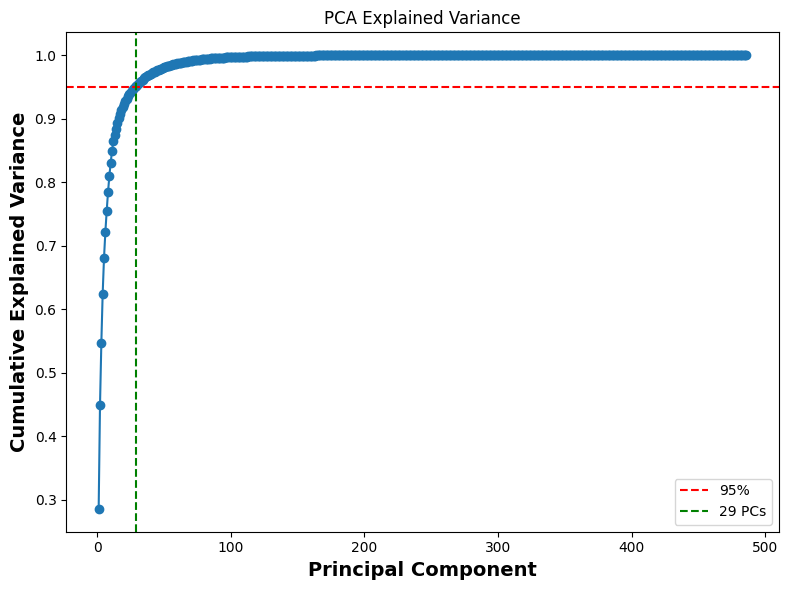

In [ ]:
plt.figure(figsize=(8,6))

plt.plot(
    range(1,len(cum_var)+1),
    cum_var,
    marker='o'
)

plt.axhline(
    0.95,
    color='red',
    linestyle='--',
    label='95%'
)

plt.axvline(
    n95,
    color='green',
    linestyle='--',
    label=f'{n95} PCs'
)

plt.xlabel("Principal Component",  fontsize=14, fontweight='bold')

plt.ylabel("Cumulative Explained Variance", fontsize=14, fontweight='bold')

plt.title("PCA Explained Variance")

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# PART 6. PCA Projection
# ==========================================================

pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({

    "PC1":X_pca[:,0],
    "PC2":X_pca[:,1]

})

# copy metadata
for col in df.columns:

    if col not in ftir_cols:

        pca_df[col] = df[col]

print(
    pca.explained_variance_ratio_
)

[0.28542496 0.16309937]


In [ ]:
# ==========================================================
# PART 7. PCA Loading
# ==========================================================

loading = pd.DataFrame(

    pca.components_.T,

    index=wavenumbers,

    columns=["PC1","PC2"]

)

loading.head()

,PC1,PC2
4000.291,0.000025,0.003192
3999.809,-0.001976,0.002299
3999.326,-0.003594,0.001236
3998.844,-0.004610,0.000310
3998.362,-0.005168,-0.000291


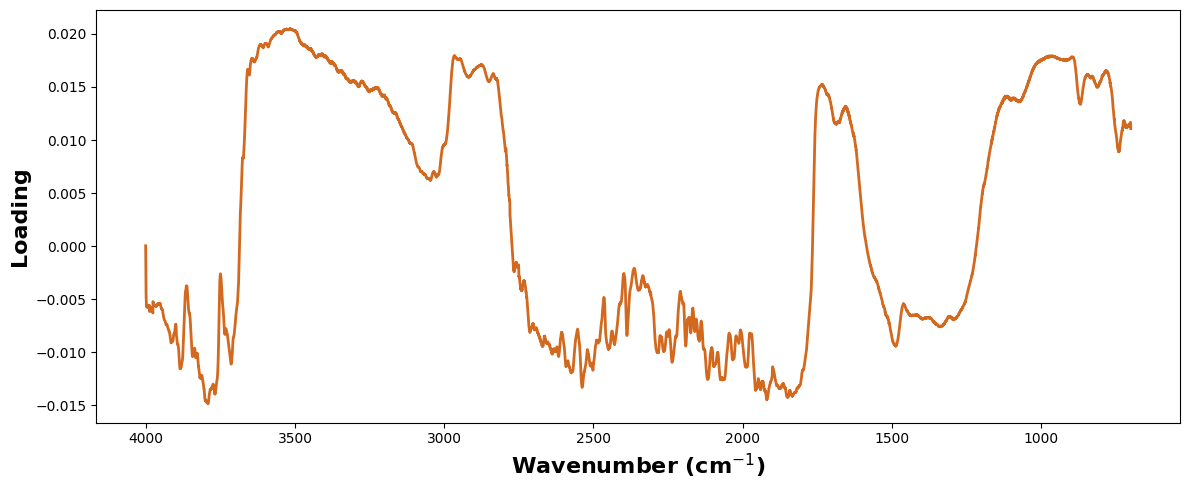

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    loading.index,
    loading["PC1"],
    linewidth=2,
    color='#D2691E'
)

plt.gca().invert_xaxis()

plt.xlabel("Wavenumber (cm$^{-1}$)", fontsize=16, fontweight='bold')

plt.ylabel("Loading", fontsize=16, fontweight='bold')

plt.tight_layout()

plt.show()

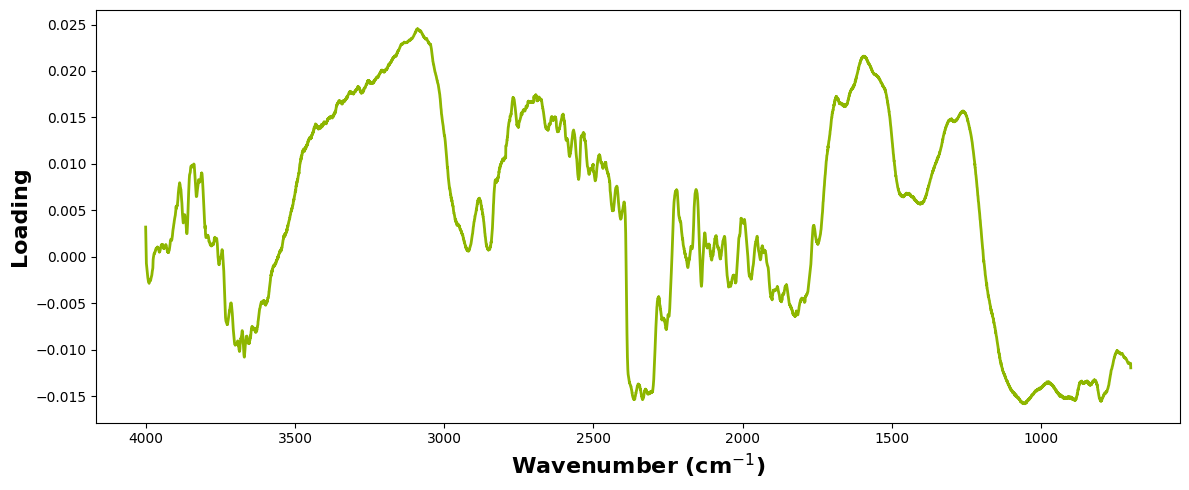

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    loading.index,
    loading["PC2"],
    linewidth=2,
    color='#8DB600'
)

plt.gca().invert_xaxis()

plt.xlabel("Wavenumber (cm$^{-1}$)", fontsize=16, fontweight='bold')

plt.ylabel("Loading", fontsize=16, fontweight='bold')

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# PART 8. Most Influential Wavenumbers
# ==========================================================

top_pc1 = (

    loading["PC1"]

    .abs()

    .sort_values(ascending=False)

    .head(20)

)

display(top_pc1)

top_pc2 = (

    loading["PC2"]

    .abs()

    .sort_values(ascending=False)

    .head(20)

)

display(top_pc2)

,PC1
3516.707,0.020491
3515.261,0.020483
3514.779,0.020479
3517.672,0.020471
3517.189,0.020466
3526.832,0.020464
3527.796,0.020461
3511.404,0.020461
3516.225,0.020451
3515.743,0.020450


,PC2
3089.534,0.024543
3088.570,0.024510
3090.980,0.024498
3087.605,0.024497
3087.123,0.024496
3090.498,0.024489
3090.016,0.024480
3088.088,0.024475
3086.641,0.024454
3086.159,0.024452


In [ ]:
# ==========================================================
# PART 9. UMAP Hyperparameter Optimization
# ==========================================================

import itertools

neighbors_list = [10, 20, 30, 50]
min_dist_list = [0.0, 0.1, 0.3, 0.5]

results = []

# Label yang akan dievaluasi
labels = {
    "Biomass": df["biomass"], # Corrected column name to 'biomass'
    "Temperature": df["temp"], # Corrected column name to 'temp'
  }

for n, md in itertools.product(neighbors_list, min_dist_list):

    reducer = umap.UMAP(
        n_neighbors=n,
        min_dist=md,
        metric="euclidean",
        random_state=RANDOM_STATE
    )

    embedding = reducer.fit_transform(X_scaled)

    row = {
        "n_neighbors": n,
        "min_dist": md
    }

    # Hitung silhouette untuk setiap label
    for label_name, label_value in labels.items():

        try:
            score = silhouette_score(
                embedding,
                label_value
            )
        except:
            score = np.nan

        row[label_name] = score

    # rata-rata keseluruhan
    row["Average"] = np.nanmean([
        row["Biomass"],
        row["Temperature"]
    ])

    results.append(row)

results = pd.DataFrame(results)

results = results.sort_values(
    by="Average",
    ascending=False
)

results.reset_index(drop=True, inplace=True)

results.head(10)

,n_neighbors,min_dist,Biomass,Temperature,Average
0,20,0.0,0.321291,-0.057509,0.131891
1,20,0.1,0.313057,-0.050352,0.131352
2,20,0.3,0.304968,-0.051679,0.126645
3,20,0.5,0.271167,-0.054720,0.108224
4,30,0.0,0.249794,-0.059907,0.094943
5,30,0.1,0.243377,-0.067979,0.087699
6,30,0.3,0.204848,-0.053811,0.075518
7,50,0.3,0.131337,-0.049291,0.041023
8,30,0.5,0.130488,-0.048879,0.040804
9,50,0.5,0.121791,-0.044668,0.038562


In [ ]:
# ==========================================================
# PART 10. Best UMAP Parameter
# ==========================================================

best = results.iloc[0]

print("="*50)
print("Best UMAP Parameter")
print("="*50)

print(best)

Best UMAP Parameter
n_neighbors    20.000000
min_dist        0.000000
Biomass         0.321291
Temperature    -0.057509
Average         0.131891
Name: 0, dtype: float64


In [ ]:
# ==========================================================
# PART 11. Best UMAP Embedding
# ==========================================================

best_umap = umap.UMAP(

    n_neighbors=int(best["n_neighbors"]),

    min_dist=float(best["min_dist"]),

    metric="euclidean",

    random_state=RANDOM_STATE

)

embedding = best_umap.fit_transform(X_scaled)

umap_df = pd.DataFrame({

    "UMAP1": embedding[:,0],

    "UMAP2": embedding[:,1]

})

# Tambahkan metadata
for col in df.columns:

    if col not in ftir_cols:

        umap_df[col] = df[col]

umap_df.head()

,UMAP1,UMAP2,sample_id,biomass,temp,replicate,y_idig,peak_OH,peak_CC_1600,peak_CO_1700,peak_CO_1050,peak_CH_2920,ratio_OH_CC,ratio_CO_CC,ratio_CH_CC
0,-4.090483,4.863040,200_1,Sugar-apple Seed,200,1,0.886520,5.907780,2.567610,14.465640,1.384130,0.216640,2.300887,6.172966,0.084374
1,-4.101754,4.819877,200_1,Sugar-apple Seed,200,2,0.851280,5.510390,2.693430,16.649050,1.466970,0.253510,2.045863,6.726004,0.094122
2,-0.557156,-4.529940,200_2,Sugar-apple Seed,200,3,0.892340,5.907780,2.567610,14.465640,1.384130,0.216640,2.300887,6.172966,0.084374
3,-4.091522,4.860569,200_4,Sugar-apple Seed,200,4,0.882533,6.206852,2.474513,14.526912,1.349543,0.204830,2.318375,6.478316,0.083791
4,-4.077154,4.853099,200_5,Sugar-apple Seed,200,5,0.885443,5.865407,2.514734,14.461602,1.446849,0.209381,2.214131,5.933809,0.085143


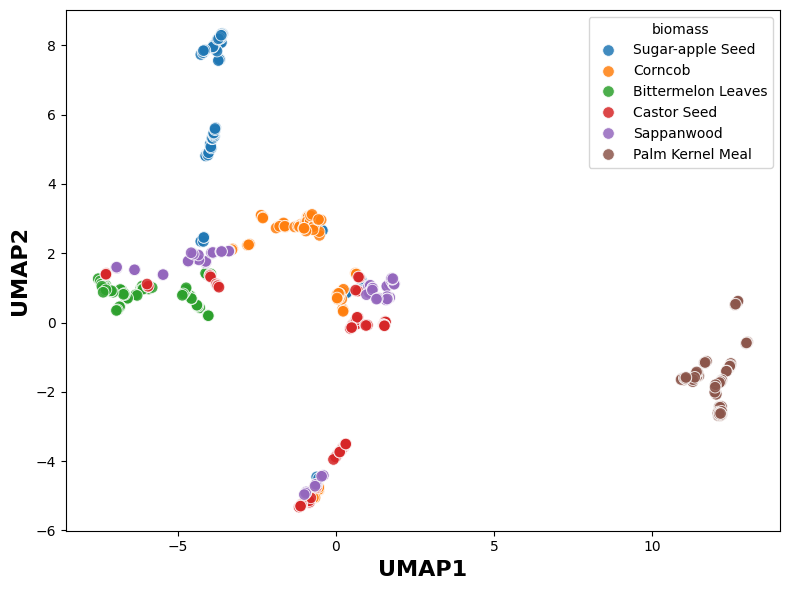

In [ ]:
# ==========================================================
# PART 12. UMAP by Biomass
# ==========================================================

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="biomass", # Diubah dari 'Biomass' ke 'biomass' agar sesuai dengan kolom dataframe
    s=70,
    alpha=0.85
)

# Mengatur label sumbu X dan Y dengan fontsize dan fontweight yang benar
plt.xlabel("UMAP1", fontsize=16, fontweight='bold')
plt.ylabel("UMAP2", fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

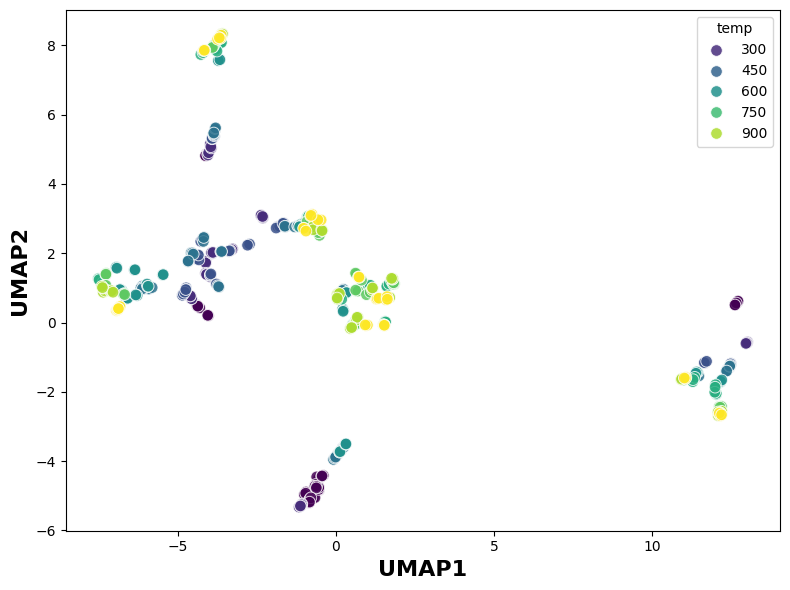

In [ ]:
# ==========================================================
# PART 13. UMAP by Temperature (Sorted for Proper Gradient)
# ==========================================================

plt.figure(figsize=(8,6))

# Mengurutkan umap_df berdasarkan 'temp' agar gradasi warna teratur dari 200 ke 1000
umap_df_sorted = umap_df.sort_values("temp")

sns.scatterplot(
    data=umap_df_sorted,
    x="UMAP1",
    y="UMAP2",
    hue="temp",
    palette="viridis",
    s=70,
    alpha=0.85
)

# Mengatur label sumbu X dan Y dengan fontsize dan fontweight yang benar
plt.xlabel("UMAP1", fontsize=16, fontweight='bold')
plt.ylabel("UMAP2", fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# PART 15. Hyperparameter Ranking
# ==========================================================

results.round(4)

,n_neighbors,min_dist,Biomass,Temperature,Average
0,20,0.0,0.3213,-0.0575,0.1319
1,20,0.1,0.3131,-0.0504,0.1314
2,20,0.3,0.3050,-0.0517,0.1266
3,20,0.5,0.2712,-0.0547,0.1082
4,30,0.0,0.2498,-0.0599,0.0949
5,30,0.1,0.2434,-0.0680,0.0877
6,30,0.3,0.2048,-0.0538,0.0755
7,50,0.3,0.1313,-0.0493,0.0410
8,30,0.5,0.1305,-0.0489,0.0408
9,50,0.5,0.1218,-0.0447,0.0386


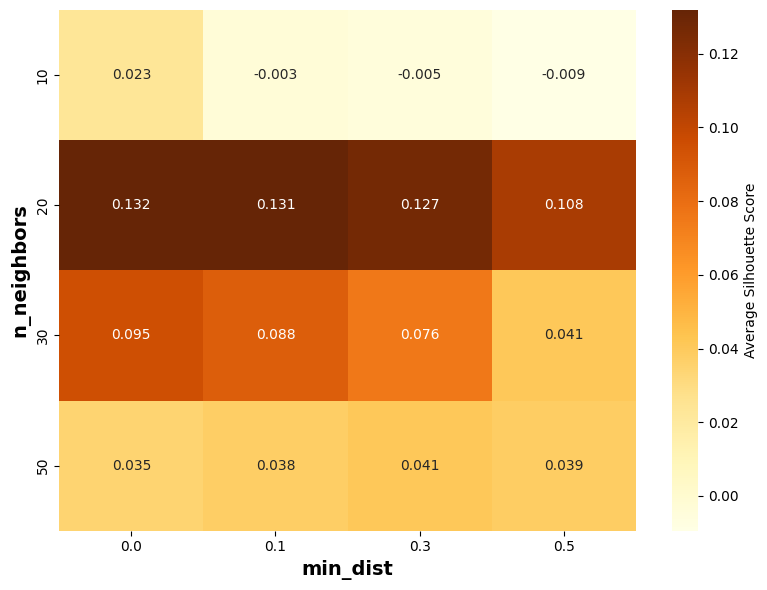

In [ ]:
# ==========================================================
# PART 16. Hyperparameter Heatmap (MAPLE Theme)
# ==========================================================

# Membuat pivot table murni tanpa parameter visualisasi
pivot = results.pivot_table(
    index="n_neighbors",
    columns="min_dist",
    values="Average"
)

plt.figure(figsize=(8,6))

# Membuat heatmap
sns.heatmap(
    pivot,
    annot=True,
    cmap="YlOrBr",
    fmt=".3f",
    cbar_kws={'label': 'Average Silhouette Score'}
)

# Mengatur label sumbu X dan Y dengan ukuran dan ketebalan huruf yang benar
plt.xlabel("min_dist", fontsize=14, fontweight='bold')
plt.ylabel("n_neighbors", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

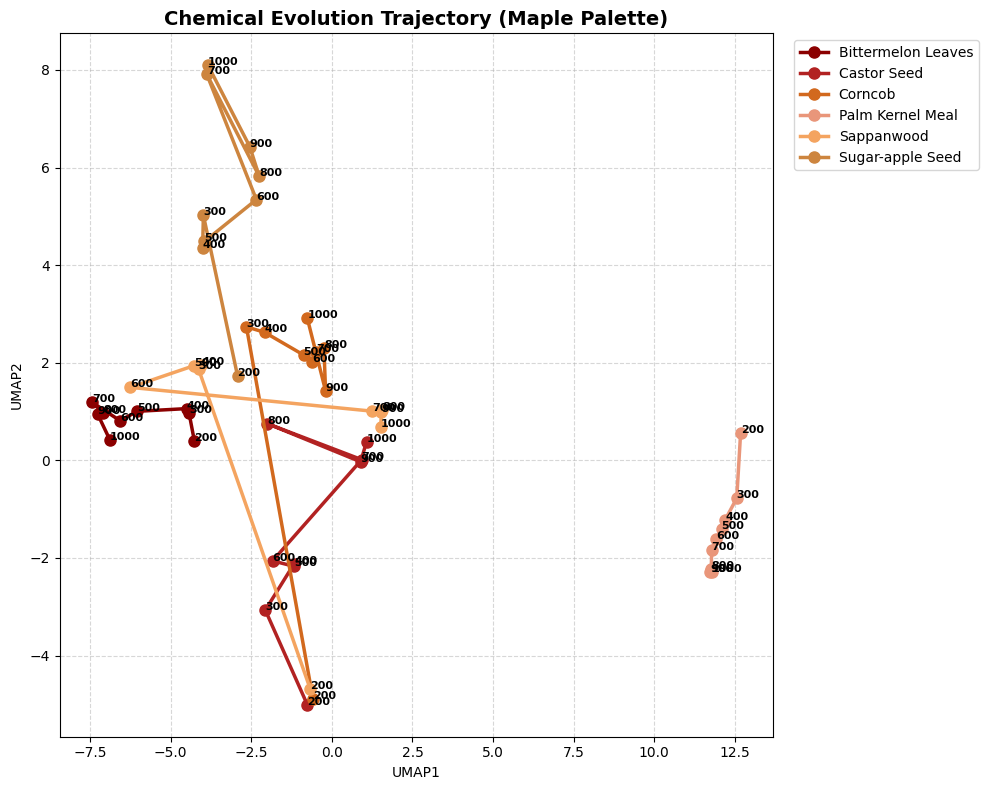

In [ ]:
# ==========================================================
# PART 17B. Plot Chemical Evolution Trajectory (MAPLE Theme)
# ==========================================================

# Calculate centroids by grouping umap_df by biomass and temperature
centroids = (
    umap_df.groupby(["biomass", "temp"])[["UMAP1", "UMAP2"]]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10,8))

# Mendefinisikan palet warna hangat khas daun maple
maple_colors = ["#8B0000", "#B22222", "#D2691E", "#E9967A", "#F4A460", "#CD853F"]
unique_biomass = sorted(centroids["biomass"].unique())
palette_maple = sns.color_palette(maple_colors, len(unique_biomass))

for color, biomass in zip(palette_maple, unique_biomass):

    sub = centroids[centroids["biomass"]==biomass]

    sub = sub.sort_values("temp")

    plt.plot(
        sub["UMAP1"],
        sub["UMAP2"],
        "-o",
        linewidth=2.5,
        markersize=8,
        color=color,
        label=biomass
    )

    # label temperature
    for _, row in sub.iterrows():

        plt.text(
            row["UMAP1"],
            row["UMAP2"],
            str(row["temp"]),
            fontsize=8,
            weight='semibold'
        )

plt.xlabel("UMAP1")

plt.ylabel("UMAP2")

plt.title("Chemical Evolution Trajectory (Maple Palette)", fontsize=14, weight='bold')

plt.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left"
)

plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# PART 18. Total Trajectory Length
# ==========================================================

trajectory = []

for biomass in sorted(centroids["biomass"].unique()): # Changed "Biomass" to "biomass"

    sub = centroids[centroids["biomass"]==biomass] # Changed "Biomass" to "biomass"

    sub = sub.sort_values("temp") # Changed "Temperature" to "temp"

    coords = sub[["UMAP1","UMAP2"]].values

    total = 0

    for i in range(len(coords)-1):

        d = np.linalg.norm(coords[i+1]-coords[i])

        total += d

    trajectory.append({

        "Biomass": biomass,

        "Trajectory_Length": total

    })

trajectory = pd.DataFrame(trajectory)

trajectory = trajectory.sort_values(
    "Trajectory_Length",
    ascending=False
)

trajectory

,Biomass,Trajectory_Length
4,Sappanwood,17.971600
5,Sugar-apple Seed,14.517059
1,Castor Seed,14.294122
2,Corncob,13.022394
0,Bittermelon Leaves,4.993035
3,Palm Kernel Meal,3.183986


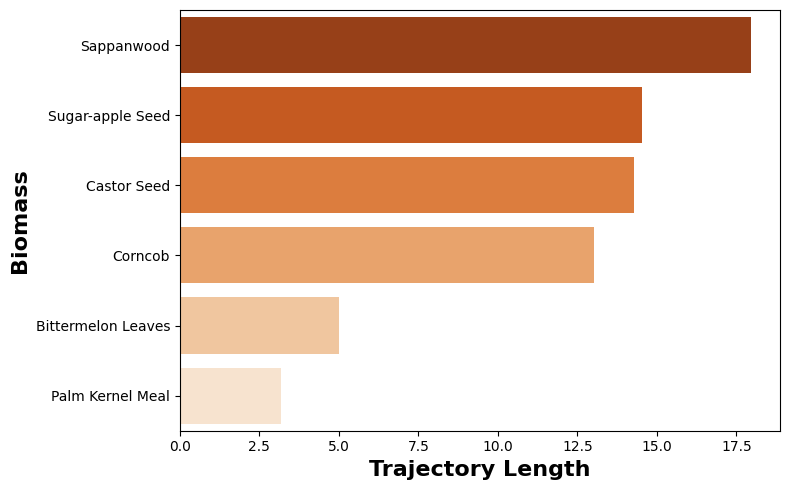

In [ ]:
# ==========================================================
# PART 18. Total Trajectory Length Barplot (MAPLE Theme)
# ==========================================================

plt.figure(figsize=(8,5))

sns.barplot(
    data=trajectory,
    x="Trajectory_Length",
    y="Biomass",
    palette="Oranges_r"
)

plt.xlabel("Trajectory Length", fontsize=16, fontweight='bold')

plt.ylabel("Biomass", fontsize=16, fontweight='bold')

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# PART 19. Distance Between Temperatures
# ==========================================================

records = []

for biomass in sorted(centroids["biomass"].unique()): # Changed "Biomass" to "biomass"

    sub = centroids[
        centroids["biomass"]==biomass # Changed "Biomass" to "biomass"
    ].sort_values("temp") # Changed "Temperature" to "temp"

    coords = sub[["UMAP1","UMAP2"]].values

    temps = sub["temp"].values # Changed "Temperature" to "temp"

    for i in range(len(coords)-1):

        records.append({

            "Biomass": biomass,

            "Transition": f"{temps[i]} → {temps[i+1]}",

            "Distance": np.linalg.norm(
                coords[i+1]-coords[i]
            )

        })

step_distance = pd.DataFrame(records)

step_distance

,Biomass,Transition,Distance
0,Bittermelon Leaves,200 → 300,0.596132
1,Bittermelon Leaves,300 → 400,0.127998
2,Bittermelon Leaves,400 → 500,1.522604
3,Bittermelon Leaves,500 → 600,0.576285
4,Bittermelon Leaves,600 → 700,0.941633
5,Bittermelon Leaves,700 → 800,0.404112
6,Bittermelon Leaves,800 → 900,0.166513
7,Bittermelon Leaves,900 → 1000,0.657758
8,Castor Seed,200 → 300,2.335714
9,Castor Seed,300 → 400,1.310350


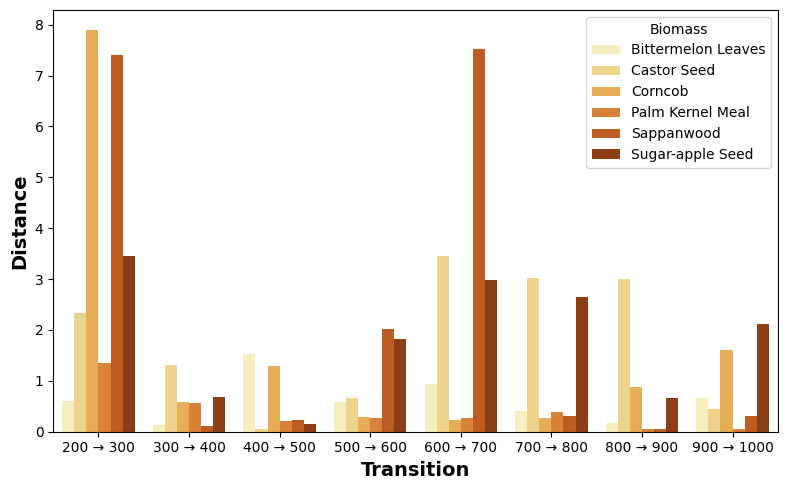

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=step_distance,
    x="Transition",
    y="Distance",
    hue="Biomass",
    palette="YlOrBr"
)

plt.xlabel("Transition", fontsize=14, fontweight='bold')
plt.ylabel("Distance", fontsize=14, fontweight='bold')

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# PART 20. Universal Convergence Index
# ==========================================================

from scipy.spatial.distance import pdist

records = []

for temp in sorted(centroids["temp"].unique()): # Changed "Temperature" to "temp"

    sub = centroids[
        centroids["temp"]==temp # Changed "Temperature" to "temp"
    ]

    coords = sub[["UMAP1","UMAP2"]].values

    mean_distance = pdist(coords).mean()

    records.append({

        "Temperature": temp,

        "Mean_Centroid_Distance": mean_distance

    })

convergence = pd.DataFrame(records)

convergence

,Temperature,Mean_Centroid_Distance
0,200,7.894448
1,300,8.076446
2,400,7.631618
3,500,8.163003
4,600,8.704642
5,700,8.982489
6,800,8.259982
7,900,8.402320
8,1000,9.024273


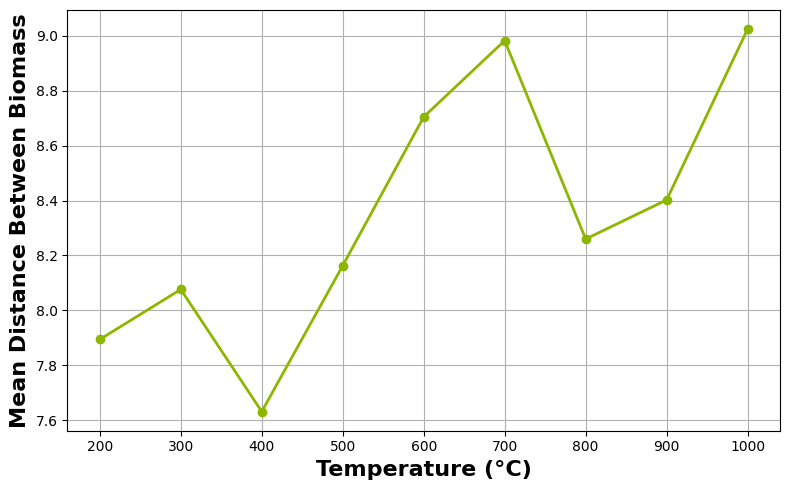

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    convergence["Temperature"],
    convergence["Mean_Centroid_Distance"],
    marker="o",
    linewidth=2,
    color='#8DB600'
)

plt.xlabel("Temperature (°C)", fontsize=16, fontweight='bold')

plt.ylabel("Mean Distance Between Biomass", fontsize=16, fontweight='bold')

plt.grid(True)

plt.tight_layout()

plt.show()